# Exploratory analysis - QuantML Research Platform

This notebook explores one instrument's daily history and walks through the research pipeline
using the same `quantml` package as the dashboard. Every number is computed from the data loaded
below; nothing is hard-coded.

* Default data: SPY from Yahoo Finance (cached under `data/raw/`). If the download fails, the
  notebook falls back to **clearly labelled synthetic data**, which is not real market data.
* Stored outputs come from one run of this notebook (see the data summary in the first output);
  re-running it with `pip install -r requirements-dev.txt` reproduces them from the cached data.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

import pandas as pd
import plotly.io as pio
try:  # static PNG charts so the stored outputs also render on GitHub
    import kaleido  # noqa: F401
    pio.renderers.default = "png"
    pio.renderers["png"].width, pio.renderers["png"].height = 1000, 420
except ImportError:
    pio.renderers.default = "notebook_connected"
from quantml import eda, visualization as viz
from quantml.config import load_config
from quantml.data_loader import DataLoadError
from quantml.features import audit_lookahead, build_features, feature_descriptions, volume_usable
from quantml.metrics import format_metrics_table
from quantml.pipeline import load_and_prepare, run_research

theme = viz.get_theme("light")
cfg = load_config()                        # config/default_config.yaml
try:
    prepared = load_and_prepare(cfg)
except DataLoadError as exc:
    print(f"Download failed ({exc}); falling back to SYNTHETIC data.")
    cfg = cfg.with_overrides({"data": {"source": "synthetic"}})
    prepared = load_and_prepare(cfg)

prices = prepared.prices
print(prepared.report.summary())
print("Source:", prepared.market.source_label, "| adjustment:", prepared.adjustment)

Data validation PASSED: 3774 valid rows (2010-01-04 to 2024-12-31).
Source: Yahoo Finance via yfinance | adjustment: Adjusted for splits and dividends: raw Open/High/Low/Close multiplied by Adj Close / Close (applied once).


## Prices versus returns

Price **levels** are non-stationary: a $5 move means something different at $100 and at $500.
Strategies earn **returns** (relative changes), so all statistics below are computed on daily
returns of the adjusted close.

In [2]:
summary = eda.return_summary(prices, cfg.evaluation.periods_per_year)
summary

,value
Observations (price rows),3774.000000
Return observations,3773.000000
Mean daily return,0.000567
Daily return volatility (std),0.010741
Annualised mean return (x periods),0.142780
Annualised volatility (x sqrt(periods)),0.170509
Minimum daily return,-0.109424
Maximum daily return,0.090603
Skewness,-0.514805
Excess kurtosis,10.772953


In [3]:
eda.statistical_tests(prices)

,test,null_hypothesis,statistic,p_value
0,"Ljung-Box (returns, 10 lags)",No autocorrelation up to the lag,180.804713,1.594741e-33
1,"Ljung-Box (squared returns, 10 lags)",No volatility clustering,4822.485011,0.000000e+00
2,Jarque-Bera,Returns are normally distributed,18411.709163,0.000000e+00


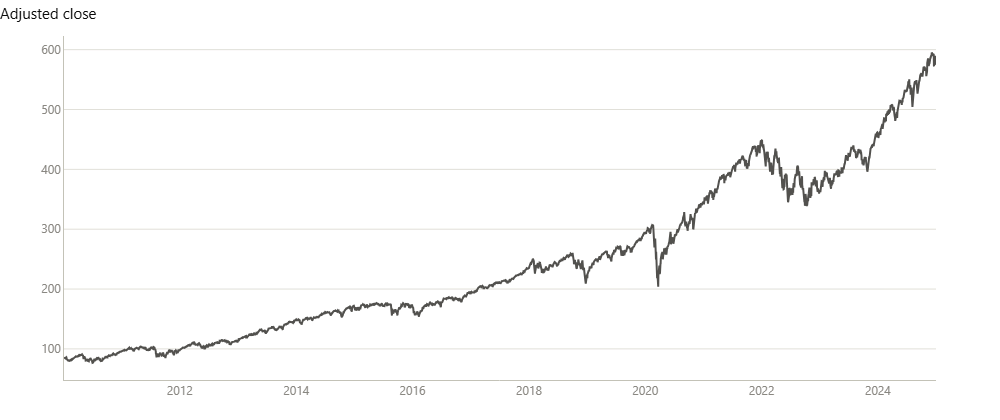

In [4]:
viz.price_chart(prices, theme)

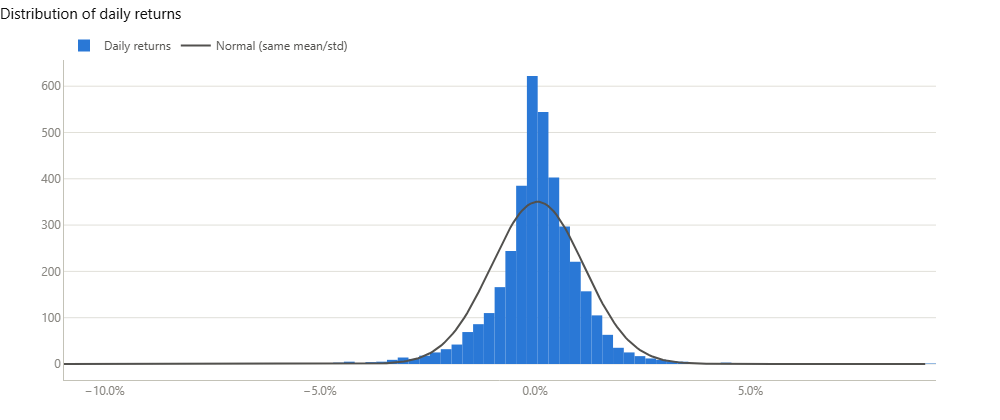

In [5]:
returns = eda.daily_returns(prices)
viz.return_histogram(returns, theme)

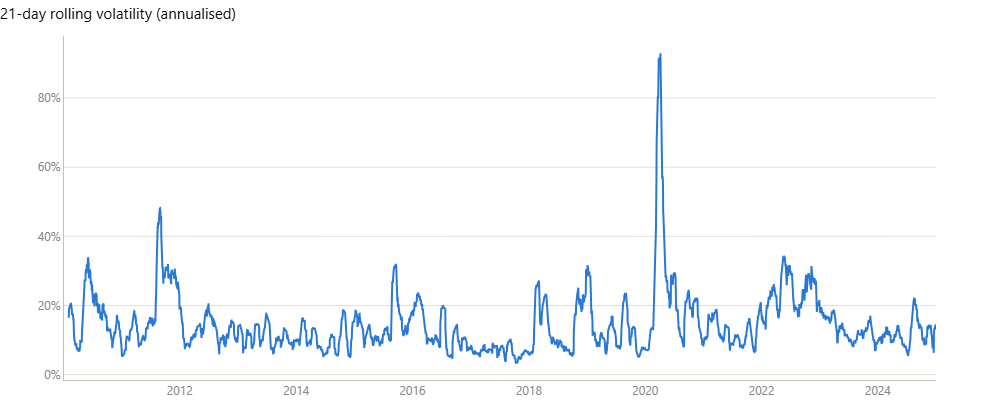

In [6]:
rolling = eda.rolling_statistics(prices, 21, cfg.evaluation.periods_per_year)
viz.line_chart(rolling["rolling_volatility_ann"], theme, "21-day rolling volatility (annualised)", ".0%")

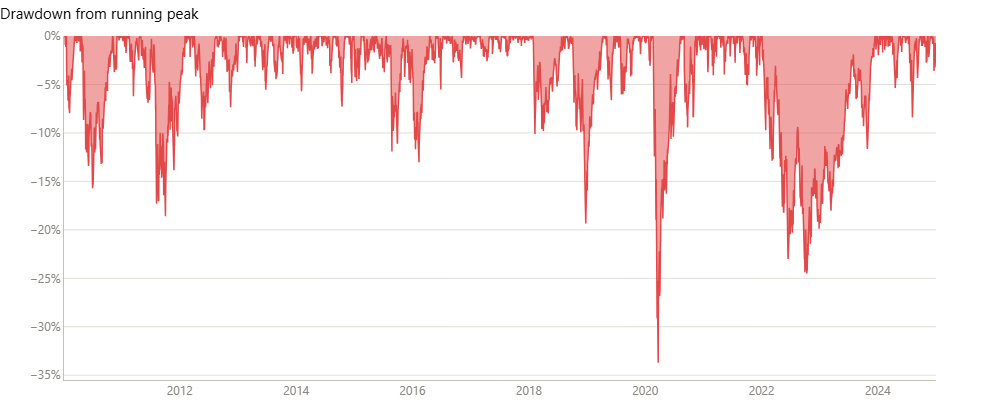

In [7]:
viz.area_drawdown_chart(eda.price_drawdown(prices), theme, "Drawdown from running peak")

## Features and the look-ahead audit

Every feature dated *t* uses information up to the close of *t*. The audit recomputes features on
history truncated at sampled dates and checks they are unchanged - a feature that used future
data would differ.

In [8]:
use_volume = volume_usable(prices, cfg.features)
features = build_features(prices, cfg.features, use_volume)
pd.Series(feature_descriptions(cfg.features, use_volume), name="definition").to_frame()

,definition
ret_lag_0,Close-to-close return from t-1 to t
ret_lag_1,Close-to-close return from t-2 to t-1
ret_lag_2,Close-to-close return from t-3 to t-2
ret_lag_3,Close-to-close return from t-4 to t-3
ret_lag_4,Close-to-close return from t-5 to t-4
mom_5,5-day momentum: close[t] / close[t-5] - 1
mom_10,10-day momentum: close[t] / close[t-10] - 1
mom_20,20-day momentum: close[t] / close[t-20] - 1
vol_10,Standard deviation of the last 10 daily return...
vol_20,Standard deviation of the last 20 daily return...


In [9]:
audit = audit_lookahead(prices, cfg.features)
audit

LookaheadAudit(passed=True, n_checked=25, max_abs_difference=0.0, offending_dates=[])

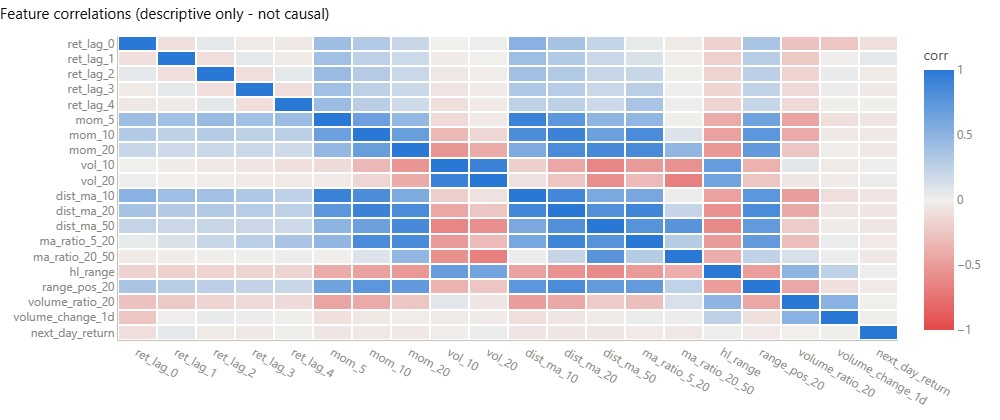

In [10]:
next_return = prices["close"].pct_change(fill_method=None).shift(-1).rename("next_day_return")
viz.correlation_heatmap(features.join(next_return).dropna(), theme,
                        "Feature correlations (descriptive only - not causal)")

## Full research pipeline

Chronological train / validation / test split with label purging, validation-only model
selection, identical execution and costs for all strategies, and walk-forward evaluation.

In [11]:
result = run_research(prices, cfg, prepared.provenance())
result.split_table

,segment,start,end,model_rows,backtest_days
0,In-sample (training period),2010-03-16,2019-01-29,2233,2234
1,Validation (used for model choices),2019-01-30,2022-01-10,743,744
2,Out-of-sample (untouched test period),2022-01-11,2024-12-31,746,747


In [12]:
format_metrics_table(result.segments["test"].metrics)

,Buy & Hold,MA Crossover (20/50),ML (Logistic Regression)
Start date,2022-01-11,2022-01-11,2022-01-11
End date,2024-12-31,2024-12-31,2024-12-31
Trading days,747,747,747
Cumulative return (net),29.82%,-1.62%,29.82%
Cumulative return (gross),29.86%,-1.12%,29.86%
CAGR (net),9.20%,-0.55%,9.20%
Annualised volatility,17.52%,11.68%,17.52%
Sharpe ratio (net),0.59,0.01,0.59
Sharpe ratio (gross),0.59,0.03,0.59
Maximum drawdown,-23.54%,-27.11%,-23.54%


In [13]:
format_metrics_table(result.walk_forward.metrics) if result.walk_forward is not None else None

,Buy & Hold,MA Crossover (20/50),ML (Logistic Regression)
Start date,2013-03-18,2013-03-18,2013-03-18
End date,2024-12-30,2024-12-30,2024-12-30
Trading days,"2,968","2,968","2,968"
Cumulative return (net),366.70%,139.42%,295.58%
Cumulative return (gross),366.84%,143.70%,330.61%
CAGR (net),13.97%,7.69%,12.39%
Annualised volatility,16.80%,11.31%,15.98%
Sharpe ratio (net),0.86,0.71,0.81
Sharpe ratio (gross),0.86,0.73,0.86
Maximum drawdown,-33.72%,-28.02%,-33.03%


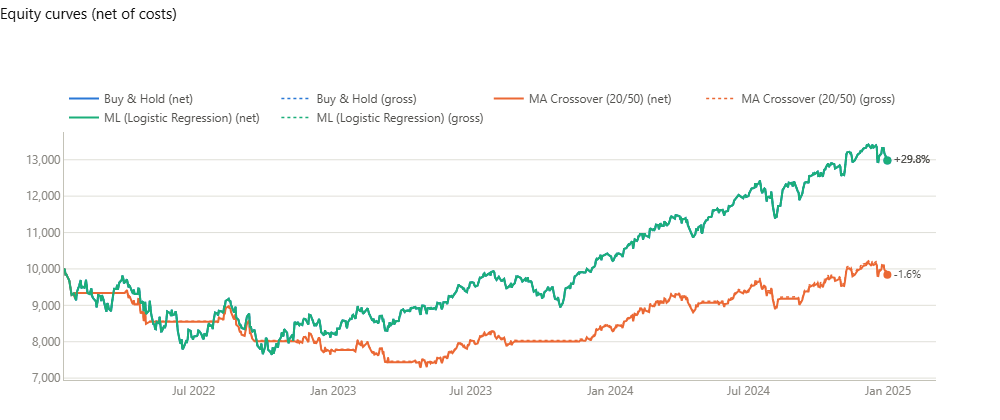

In [14]:
colors = viz.strategy_colors(list(result.signals), theme)
viz.equity_chart(result.segments["test"].backtests, colors, theme, show_gross=True)

In [15]:
pd.DataFrame({seg.label: seg.classification for seg in result.segments.values()}).drop("confusion_matrix")

,In-sample (training period),Validation (used for model choices),Out-of-sample (untouched test period)
n_count,2233,743,746
positive_rate,0.549485,0.576043,0.529491
predicted_positive_rate,0.999104,0.998654,1.0
accuracy,0.549485,0.577389,0.529491
majority_baseline_accuracy,0.549485,0.576043,0.529491
precision,0.549529,0.576819,0.529491
recall,0.999185,1.0,1.0
f1,0.70908,0.731624,0.692375
roc_auc,0.528149,0.52559,0.485023
log_loss,0.68698,0.682709,0.693908


## Reading the results honestly

* Compare the ML strategy with Buy & Hold on the **same** out-of-sample dates, net of costs.
* Accuracy should be compared with the majority-class baseline; accuracy alone does not imply
  profitability.
* One instrument and one test period are weak evidence. Check the walk-forward folds and the
  bootstrap intervals, and remember that every configuration you try adds selection bias.